In [300]:
import torch
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [301]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        return self._x[idx], self._y[idx]

In [302]:
def train_model_class(features, targets, kf, batch, epochs, max_folds=None):
    accuracy_scores = []
    f1_scores = []
    folds_loss = []
    folds_acc = [] 
    for i, (train_index, test_index) in enumerate(kf.split(features, targets)):
        # Limita o número de folds (útil para análise inicial rápida)
        if max_folds is not None and i >= max_folds:
            break

        print(f"\nTreinando modelo ----- Fold {i + 1}")

        # Separar treino e teste
        X_train, X_test = features[train_index], features[test_index]
        y_train, y_test = targets[train_index], targets[test_index]

        # Padronização: fit SOMENTE no treino, transform nos dois
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train).astype(np.float32)
        X_test = scaler.transform(X_test).astype(np.float32)

        # Criar um modelo novo para cada fold
        model = Sequential(
            Linear(13, 32),
            ReLU(),
            Linear(32, 16),
            ReLU(),
            Linear(16, 3)
        )
        optmizer = Adam(model.parameters(), lr=0.001)
        criterion = CrossEntropyLoss()

        # Preparar os dados de treinamento (já padronizados)
        train_data = MyDataset(X_train, y_train)
        train_loader = DataLoader(train_data, batch_size=batch, shuffle=True)
        epoch_loss = []
        epoch_acc = []   

        # Treinar o modelo
        for i_epochs in range(epochs):
            model.train()
            batches_loss = []  
            batches_acc = [] 

            for x, y in train_loader:
                optmizer.zero_grad()

                output = model(x)
                loss = criterion(output, y)

                loss.backward()
                optmizer.step()
                batches_loss.append(loss.item())  
                batches_acc.append((output.argmax(dim=1) == y).float().mean().item())  

            epoch_loss.append(np.mean(batches_loss))  
            epoch_acc.append(np.mean(batches_acc))    

        folds_loss.append(epoch_loss)  
        folds_acc.append(epoch_acc)    
        # Avaliar o modelo
        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(X_test).float()
            y_true = y_test
            result = model(x_test_tensor)
            y_pred = result.argmax(dim=1).cpu().numpy()

            accuracy_s = accuracy_score(y_true, y_pred)
            f1_s = f1_score(y_true, y_pred, average="macro")

            accuracy_scores.append(accuracy_s)
            f1_scores.append(f1_s)

            print(f"Accuracy: {accuracy_s:.4f}")
            print(f"F1-score: {f1_s:.4f}")
            print("Matriz de confusão:")
            print(confusion_matrix(y_true, y_pred))

    print(
        f"\nResultado médio do modelo ({len(accuracy_scores)} fold(s)) ----- "
        f"Accuracy: {np.mean(accuracy_scores):.4f}, "
        f"F1-score: {np.mean(f1_scores):.4f}"
    )
    return folds_loss, folds_acc

In [303]:
dataset = load_wine()
features = dataset.data
targets = dataset.target

In [304]:
print(dataset.data.shape)  

(178, 13)


In [305]:
# Configurações do treinamento
max_epochs = 75
batch = 8
# Configurar a validação cruzada
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# Validação cruzada completa
# folds_loss, folds_acc = train_model_class(features, targets, kf, batch=batch, epochs=max_epochs)

In [306]:
def plot_loss(folds_loss, folds_acc):
    for idx, (fold_l, fold_a) in enumerate(zip(folds_loss, folds_acc)):
        x = np.arange(1, len(fold_l) + 1)

        fig, ax1 = plt.subplots(figsize=(8, 4))
        l1, = ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        ax1.set_xlim(20, len(fold_l))
        ax1.set_ylim(0, 0.2)
        
        ax2 = ax1.twinx()
        l2, = ax2.plot(x, np.array(fold_a) * 100, color="blue", label="Acurácia")
        ax2.set_ylabel("Acurácia (%)")
        ax2.grid(alpha=0.3)
        ax2.set_ylim(90, 101)
        ax1.legend(handles=[l1, l2], loc="center right")
        plt.title(f"Fold {idx + 1}")
        plt.tight_layout()

    plt.show()


Treinando modelo ----- Fold 1
Accuracy: 0.9722
F1-score: 0.9718
Matriz de confusão:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Resultado médio do modelo (1 fold(s)) ----- Accuracy: 0.9722, F1-score: 0.9718


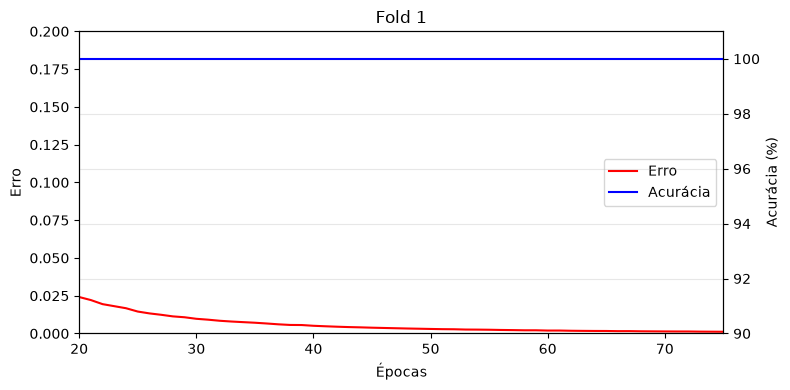

In [307]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch=batch, epochs=max_epochs, max_folds=1)
plot_loss(folds_loss, folds_acc)

In [308]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch=batch, epochs=max_epochs)


Treinando modelo ----- Fold 1
Accuracy: 0.9722
F1-score: 0.9718
Matriz de confusão:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Treinando modelo ----- Fold 2
Accuracy: 0.9722
F1-score: 0.9718
Matriz de confusão:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]

Treinando modelo ----- Fold 3
Accuracy: 0.9722
F1-score: 0.9710
Matriz de confusão:
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]

Treinando modelo ----- Fold 4
Accuracy: 0.9714
F1-score: 0.9743
Matriz de confusão:
[[12  0  0]
 [ 1 13  0]
 [ 0  0  9]]

Treinando modelo ----- Fold 5
Accuracy: 1.0000
F1-score: 1.0000
Matriz de confusão:
[[11  0  0]
 [ 0 15  0]
 [ 0  0  9]]

Resultado médio do modelo (5 fold(s)) ----- Accuracy: 0.9776, F1-score: 0.9778
